# Phase 4: Behavioural Fingerprinting for AML Fraud Detection

This notebook builds behavioral fingerprints from the engineered account feature table and evaluates how those fingerprints cluster and drift over time.

Two main tasks:
1. **Train behavior representation and clustering models** (account-level fingerprints)
2. **Behavior consistency and shift detection** (time-windowed fingerprints)

Feature definitions and field meanings are documented in `../data/DATA_DICTIONARY.md`.

In [1]:
# Imports
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report
from sklearn.metrics import confusion_matrix

from scipy.stats import ks_2samp
from scipy.spatial.distance import jensenshannon

warnings.filterwarnings('ignore')
sns.set(style='whitegrid')
%matplotlib inline
np.random.seed(42)

## Step 1 — Load behavioral feature table

We load the account-level behavioral features engineered in Phase 3. This table includes rhythm, volatility, session, and money-flow features plus the account-level label `account_money_launderer`.

We will keep labels strictly for evaluation and diagnostics; clustering itself is unsupervised.

In [2]:
DATA_DIR = os.path.join('..', 'data')
FEATURE_FILE = os.path.join(DATA_DIR, 'aml_behavior_features.csv')

if not os.path.exists(FEATURE_FILE):
    raise FileNotFoundError(f'Missing features file: {FEATURE_FILE}')

features_df = pd.read_csv(FEATURE_FILE)

print('Behavior features shape:', features_df.shape)
print('Columns:', features_df.columns.tolist())
print('Label distribution:')
print(features_df['account_money_launderer'].value_counts())

Behavior features shape: (447, 33)
Columns: ['account_id', 'tx_count', 'active_days', 'mean_gap_min', 'std_gap_min', 'night_tx_ratio', 'weekend_tx_ratio', 'burstiness_cv', 'amt_mean', 'amt_median', 'amt_std', 'amt_max', 'amt_p95', 'amt_p05', 'amt_cv', 'amt_p95_p05_spread', 'amt_max_to_median', 'session_count', 'avg_session_duration_min', 'median_tx_per_session', 'max_tx_per_session', 'avg_counterparties_per_session', 'in_amount_total', 'in_tx_count', 'in_unique_counterparties', 'out_amount_total', 'out_tx_count', 'out_unique_counterparties', 'net_flow', 'out_in_ratio', 'tx_out_ratio', 'transfer_action_share', 'account_money_launderer']
Label distribution:
account_money_launderer
1    297
0    150
Name: count, dtype: int64


## Step 2 — Define feature groups and preprocessing

We group features by behavioral theme to keep interpretations aligned with the data dictionary. We then clean, impute, and scale numeric columns for downstream representation learning.

Scaling is required because clustering and PCA are sensitive to feature magnitude differences.

In [3]:
feature_groups = {
    'rhythm': [
        'tx_count','active_days','mean_gap_min','std_gap_min',
        'night_tx_ratio','weekend_tx_ratio','burstiness_cv'
    ],
    'volatility': [
        'amt_mean','amt_median','amt_std','amt_max','amt_p95','amt_p05',
        'amt_cv','amt_p95_p05_spread','amt_max_to_median'
    ],
    'session': [
        'session_count','avg_session_duration_min','median_tx_per_session',
        'max_tx_per_session','avg_counterparties_per_session'
    ],
    'money_flow': [
        'in_amount_total','in_tx_count','in_unique_counterparties',
        'out_amount_total','out_tx_count','out_unique_counterparties',
        'net_flow','out_in_ratio','tx_out_ratio','transfer_action_share'
    ]
}

label_col = 'account_money_launderer'
id_col = 'account_id'

numeric_cols = [c for c in features_df.columns if c not in [id_col, label_col]]

X_raw = features_df[numeric_cols].replace([np.inf, -np.inf], np.nan)
X_raw = X_raw.fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

y = features_df[label_col].values
account_ids = features_df[id_col].values

print('Numeric feature count:', len(numeric_cols))
print('Scaled matrix shape:', X_scaled.shape)

Numeric feature count: 31
Scaled matrix shape: (447, 31)


# Task 1 — Train behavior representation and clustering models

This section learns compact representations (embeddings) and clusters accounts into behavioral fingerprints. We compare multiple clustering methods and evaluate alignment with the AML label for sanity checking.

## Step 3 — PCA embeddings + KMeans clustering

We use PCA to build both 2D (for visualization) and 10D (for clustering) embeddings. We then scan several K values and pick the best by silhouette score.

Best K by silhouette: 7


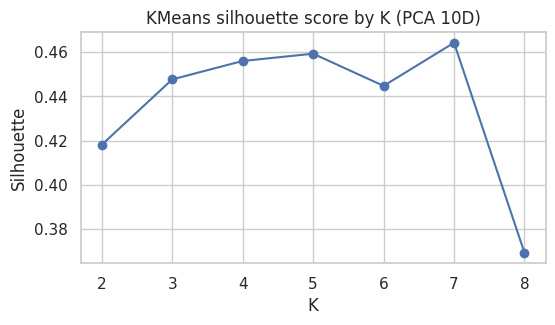

Davies-Bouldin: 0.8131737883645639
         size  aml_rate
cluster                
0         213  1.000000
1          58  0.224138
2          26  1.000000
3           9  1.000000
4           1  1.000000
5          10  1.000000
6         130  0.192308


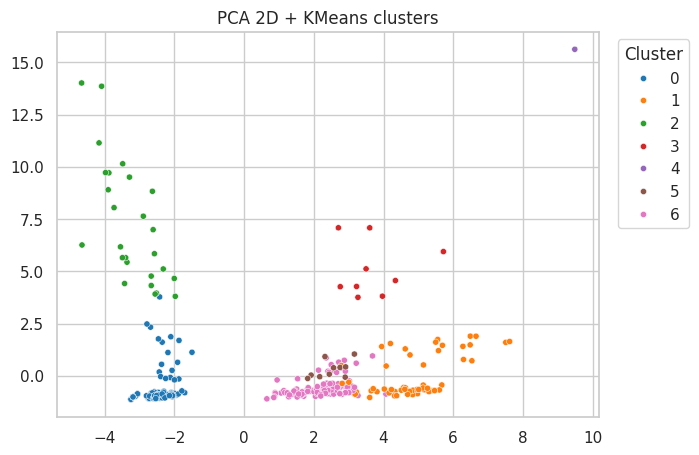

In [4]:
pca_2d = PCA(n_components=2, random_state=42)
pca_10d = PCA(n_components=10, random_state=42)

X_pca_2d = pca_2d.fit_transform(X_scaled)
X_pca_10d = pca_10d.fit_transform(X_scaled)

k_candidates = list(range(2, 9))
sil_scores = []

for k in k_candidates:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_pca_10d)
    sil_scores.append(silhouette_score(X_pca_10d, labels))

best_k = k_candidates[int(np.argmax(sil_scores))]
print('Best K by silhouette:', best_k)

plt.figure(figsize=(6, 3))
plt.plot(k_candidates, sil_scores, marker='o')
plt.title('KMeans silhouette score by K (PCA 10D)')
plt.xlabel('K')
plt.ylabel('Silhouette')
plt.show()

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca_10d)

print('Davies-Bouldin:', davies_bouldin_score(X_pca_10d, kmeans_labels))

cluster_stats = pd.DataFrame({
    'cluster': kmeans_labels,
    'account_money_launderer': y
}).groupby('cluster').agg(
    size=('account_money_launderer','size'),
    aml_rate=('account_money_launderer','mean')
)
print(cluster_stats)

plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=kmeans_labels, palette='tab10', s=20)
plt.title('PCA 2D + KMeans clusters')
plt.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

### Interpretation — PCA + KMeans
In this run the silhouette curve peaks at $K=7$ (around 0.46) and drops at $K=8$, so the output selects **7 clusters** as the best balance of separation and compactness. The Davies–Bouldin score is **0.81**, which is relatively low and supports that the clusters are reasonably distinct.

The `cluster_stats` table shows that clusters 0, 2, 3, 4, and 5 have `aml_rate = 1.0`, while clusters 1 and 6 are mostly non-AML (`~0.22` and `~0.19`). That means the model is separating suspicious behavior into several tight groups, while normal behavior concentrates in a couple of larger clusters.

The PCA plot visually confirms this separation: clusters are spatially distinct, which suggests that different behavioral fingerprints are **easily separable** in the engineered feature space. For AML, this supports using cluster membership as a risk signal or as a feature for downstream scoring.

## Step 4 — Gaussian Mixture clustering baseline

Gaussian Mixture Models (GMM) provide a soft clustering baseline. We select K by BIC and compare cluster structure and AML enrichment.

Best GMM K by BIC: 8


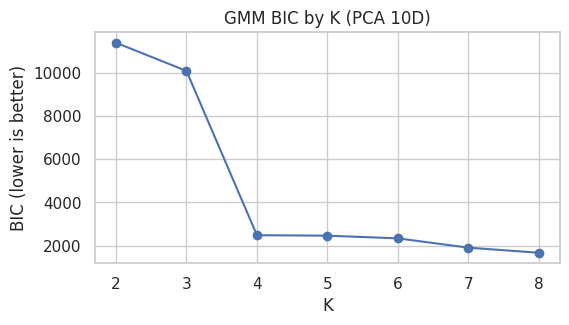

GMM silhouette: 0.3322652909887997
GMM Davies-Bouldin: 1.4307135520488772
         size  aml_rate
cluster                
0         101  0.207921
1         195  1.000000
2          54  0.240741
3          11  1.000000
4           1  1.000000
5          33  1.000000
6          35  0.171429
7          17  1.000000


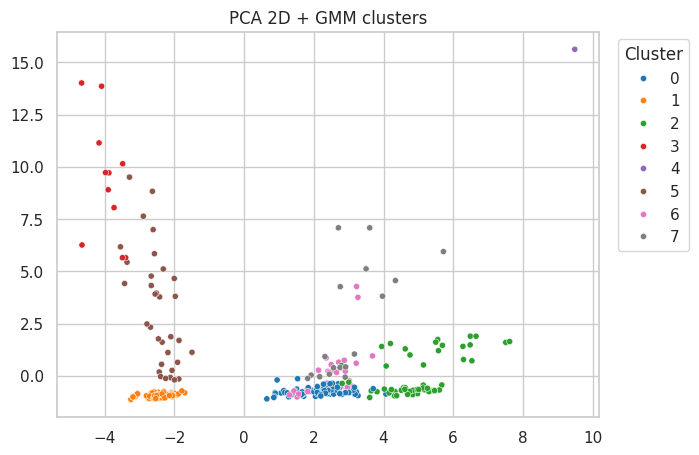

In [5]:
bic_scores = []
for k in k_candidates:
    gmm = GaussianMixture(n_components=k, random_state=42, covariance_type='full')
    gmm.fit(X_pca_10d)
    bic_scores.append(gmm.bic(X_pca_10d))

best_gmm_k = k_candidates[int(np.argmin(bic_scores))]
print('Best GMM K by BIC:', best_gmm_k)

plt.figure(figsize=(6, 3))
plt.plot(k_candidates, bic_scores, marker='o')
plt.title('GMM BIC by K (PCA 10D)')
plt.xlabel('K')
plt.ylabel('BIC (lower is better)')
plt.show()

gmm = GaussianMixture(n_components=best_gmm_k, random_state=42, covariance_type='full')
gmm_labels = gmm.fit_predict(X_pca_10d)

print('GMM silhouette:', silhouette_score(X_pca_10d, gmm_labels))
print('GMM Davies-Bouldin:', davies_bouldin_score(X_pca_10d, gmm_labels))

gmm_stats = pd.DataFrame({
    'cluster': gmm_labels,
    'account_money_launderer': y
}).groupby('cluster').agg(
    size=('account_money_launderer','size'),
    aml_rate=('account_money_launderer','mean')
)
print(gmm_stats)

plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=gmm_labels, palette='tab10', s=20)
plt.title('PCA 2D + GMM clusters')
plt.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

### Interpretation — Gaussian Mixture Model
The BIC curve drops steeply from $K=2$ to $K=4$ and then tapers, but the minimum is at **$K=8$**, so the output selects an 8-component mixture. This means the GMM favors a slightly finer partition than KMeans.

The GMM separation metrics are weaker than KMeans (silhouette **0.33**, Davies–Bouldin **1.43**), which indicates softer or overlapping clusters. The `gmm_stats` table still shows AML-enriched clusters (1, 3, 4, 5, 7 are all `aml_rate = 1.0`), while clusters 0, 2, and 6 are mostly normal.

The PCA GMM plot shows similar groupings but with more overlap, which is expected for a probabilistic model. For AML, this suggests using GMM **membership probabilities** as a nuanced risk signal rather than hard cluster labels.

## Step 5 — UMAP embeddings + HDBSCAN clustering (optional)

UMAP captures non-linear structure, and HDBSCAN discovers density-based clusters. If the packages are unavailable, the notebook skips this section gracefully.

HDBSCAN noise rate: 0.063
         size  aml_rate
cluster                
 2        175  0.217143
 4         58  1.000000
 5         57  1.000000
 0         39  1.000000
 3         36  1.000000
 6         31  1.000000
-1         28  1.000000
 1         23  0.434783


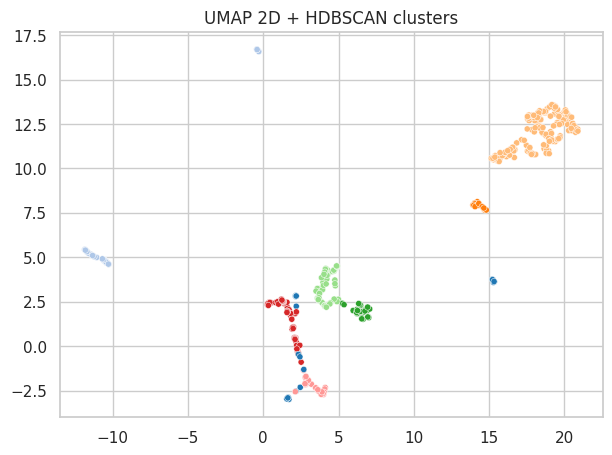

In [6]:
try:
    import umap
    import hdbscan

    umap_10d = umap.UMAP(n_components=10, random_state=42)
    umap_2d = umap.UMAP(n_components=2, random_state=42)

    X_umap_10d = umap_10d.fit_transform(X_scaled)
    X_umap_2d = umap_2d.fit_transform(X_scaled)

    clusterer = hdbscan.HDBSCAN(min_cluster_size=20, min_samples=10)
    hdb_labels = clusterer.fit_predict(X_umap_10d)

    noise_rate = np.mean(hdb_labels == -1)
    print('HDBSCAN noise rate:', round(noise_rate, 3))

    hdb_stats = pd.DataFrame({
        'cluster': hdb_labels,
        'account_money_launderer': y
    }).groupby('cluster').agg(
        size=('account_money_launderer','size'),
        aml_rate=('account_money_launderer','mean')
    ).sort_values('size', ascending=False)
    print(hdb_stats.head(10))

    plt.figure(figsize=(7, 5))
    sns.scatterplot(x=X_umap_2d[:, 0], y=X_umap_2d[:, 1], hue=hdb_labels, palette='tab20', s=20, legend=False)
    plt.title('UMAP 2D + HDBSCAN clusters')
    plt.show()
except Exception as exc:
    print('UMAP/HDBSCAN not available. Skipping this section.')
    print('Reason:', exc)

### Interpretation — UMAP + HDBSCAN (if available)
UMAP reveals nonlinear structure, and HDBSCAN discovers dense behavioral regions. In this run the **noise rate is 0.063**, meaning about 6.3% of accounts do not belong to any dense cluster.

The cluster table shows multiple AML-enriched groups: clusters 0, 3, 4, 5, 6 and the noise cluster -1 all have `aml_rate = 1.0`, while cluster 2 is mostly normal (`~0.22`) and cluster 1 is mixed (`~0.43`).

The UMAP plot shows several well-separated islands, indicating that nonlinear embeddings further separate behavior patterns. From an AML perspective, the noise points and AML-heavy clusters are prime candidates for review.

## Step 6 — Representation sanity check (supervised probe)

We probe whether the PCA embedding captures signal by training a lightweight logistic regression. This is not the final model, only a validation that the embedding is informative.

ROC-AUC: 0.9893314366998578
PR-AUC: 0.9951064026295176

Classification report:
              precision    recall  f1-score   support

           0      0.900     0.947     0.923        38
           1      0.972     0.946     0.959        74

    accuracy                          0.946       112
   macro avg      0.936     0.947     0.941       112
weighted avg      0.948     0.946     0.947       112



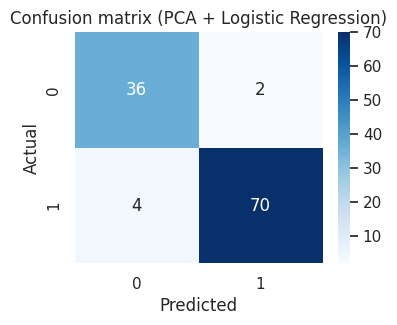

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X_pca_10d, y, test_size=0.25, random_state=42, stratify=y
)

clf = LogisticRegression(max_iter=200)
clf.fit(X_train, y_train)

y_prob = clf.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

print('ROC-AUC:', roc_auc_score(y_test, y_prob))
print('PR-AUC:', average_precision_score(y_test, y_prob))
print('')
print('Classification report:')
print(classification_report(y_test, y_pred, digits=3))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion matrix (PCA + Logistic Regression)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Interpretation — Embedding sanity check
The PCA probe reports **ROC-AUC 0.989** and **PR-AUC 0.995**, indicating the embedding is highly informative for the synthetic AML label.

From the confusion matrix, there are 36 true negatives, 2 false positives, 4 false negatives, and 70 true positives. This implies strong detection capability with only a small number of missed suspicious accounts.

This is a diagnostic, not the final detector, but it confirms the fingerprint space is meaningful for fraud pattern separation.

# Task 2 — Behavior consistency and shift detection
Behavior consistency & shift detection measures how an account’s behavioral fingerprint changes over time and whether the population’s behavior distribution drifts. It does two things:

- Per‑account consistency: builds monthly fingerprints and computes embedding distances between consecutive windows; large jumps indicate unusual behavioral change.
- Population shift: compares early vs late windows with PSI/JS/KS to detect distribution drift in key features (timing, volume, flow).


We re-aggregate behavior features by time window to detect population drift and per-account behavioral shifts. This uses the raw transaction log to build fingerprints per window.

## Step 7 — Build account-event table from transactions

We reconstruct the account-event table (incoming/outgoing views) and normalize amounts to USD. This mirrors the Phase 3 Step 2 feature engineering logic.

In [8]:
TX_FILE = os.path.join(DATA_DIR, 'aml_synthetic_data.csv')
if not os.path.exists(TX_FILE):
    raise FileNotFoundError(f'Missing transaction file: {TX_FILE}')

tx_df = pd.read_csv(TX_FILE, parse_dates=['timestamp'])

special_accounts = {'SOURCE', 'PLATFORM'}
FX_RATES = {
    'US Dollar': 1.0,        'Euro': 0.92,          'UK Pound': 0.79,
    'Swiss Franc': 0.90,     'Canadian Dollar': 1.35, 'Australian Dollar': 1.53,
    'Yuan': 7.24,            'Yen': 149.5,           'Indian Rupee': 83.1,
    'Ruble': 90.0,           'Mexican Peso': 17.1,   'Brazilian Real': 4.97,
    'Saudi Riyal': 3.75,     'Shekel': 3.68,         'Bitcoin': 0.000015,
    'Swedish Krona': 10.4
}

out_cols = [
    'transaction_id','timestamp','from_account','to_account','amount_paid',
    'session_id','payment_format','channel','action_type','money_launderer'
]
if 'paying_currency' in tx_df.columns:
    out_cols.append('paying_currency')

out_events = tx_df[out_cols].copy()
out_events = out_events.rename(columns={
    'from_account': 'account_id',
    'to_account': 'counterparty',
    'amount_paid': 'amount',
    'money_launderer': 'account_label',
    'paying_currency': 'amount_currency'
})
if 'amount_currency' not in out_events.columns:
    out_events['amount_currency'] = None
out_events['direction'] = 'out'

in_cols = [
    'transaction_id','timestamp','to_account','from_account','amount_received',
    'session_id','payment_format','channel','action_type','money_launderer'
]
if 'receiving_currency' in tx_df.columns:
    in_cols.append('receiving_currency')

in_events = tx_df[in_cols].copy()
in_events = in_events.rename(columns={
    'to_account': 'account_id',
    'from_account': 'counterparty',
    'amount_received': 'amount',
    'money_launderer': 'account_label',
    'receiving_currency': 'amount_currency'
})
if 'amount_currency' not in in_events.columns:
    in_events['amount_currency'] = None
in_events['direction'] = 'in'

account_events = pd.concat([out_events, in_events], ignore_index=True)
account_events = account_events[~account_events['account_id'].isin(special_accounts)].copy()
account_events['amount'] = pd.to_numeric(account_events['amount'], errors='coerce').fillna(0.0)
account_events['account_label'] = account_events['account_label'].fillna(False).astype(int)

fx_rate = account_events['amount_currency'].map(FX_RATES).fillna(1.0)
account_events['amount_usd'] = account_events['amount'] / fx_rate

account_events = account_events.sort_values(['account_id','timestamp']).reset_index(drop=True)

print('Account-event shape:', account_events.shape)
print('Unique accounts:', account_events['account_id'].nunique())

Account-event shape: (30247, 13)
Unique accounts: 447


### Interpretation — Account-event table
The output shows **30,247** account-events across **447** accounts after splitting each transaction into incoming and outgoing views. That matches the feature table size and confirms full coverage.

This account-event table is the basis for time-windowed fingerprints; the USD normalization ensures that drift metrics reflect behavioral shifts rather than currency mix changes.

## Step 8 — Time-windowed fingerprint aggregation

We aggregate the same behavioral features as Phase 3, but within monthly windows. Each account can therefore have multiple fingerprints over time, enabling shift detection.

In [9]:
def build_behavior_features(events_df):
    rh = events_df[['account_id','timestamp']].copy()
    rh['day'] = rh['timestamp'].dt.date
    rh['hour'] = rh['timestamp'].dt.hour
    rh['is_night'] = ((rh['hour'] < 6) | (rh['hour'] >= 22)).astype(int)
    rh['is_weekend'] = (rh['timestamp'].dt.dayofweek >= 5).astype(int)

    rh = rh.sort_values(['account_id','timestamp'])
    rh['gap_min'] = rh.groupby('account_id')['timestamp'].diff().dt.total_seconds() / 60.0

    rhythm_features = rh.groupby('account_id').agg(
        tx_count=('timestamp','size'),
        active_days=('day','nunique'),
        mean_gap_min=('gap_min','mean'),
        std_gap_min=('gap_min','std'),
        night_tx_ratio=('is_night','mean'),
        weekend_tx_ratio=('is_weekend','mean')
    ).reset_index()

    rhythm_features['burstiness_cv'] = rhythm_features['std_gap_min'] / rhythm_features['mean_gap_min'].replace(0, np.nan)
    rhythm_features = rhythm_features.fillna(0)

    vol = events_df[['account_id','amount_usd']].copy()
    vol['amount_abs'] = vol['amount_usd'].abs()

    volatility_features = vol.groupby('account_id').agg(
        amt_mean=('amount_abs','mean'),
        amt_median=('amount_abs','median'),
        amt_std=('amount_abs','std'),
        amt_max=('amount_abs','max'),
        amt_p95=('amount_abs', lambda s: np.percentile(s, 95)),
        amt_p05=('amount_abs', lambda s: np.percentile(s, 5))
    ).reset_index()

    volatility_features['amt_cv'] = volatility_features['amt_std'] / volatility_features['amt_mean'].replace(0, np.nan)
    volatility_features['amt_p95_p05_spread'] = volatility_features['amt_p95'] - volatility_features['amt_p05']
    volatility_features['amt_max_to_median'] = volatility_features['amt_max'] / volatility_features['amt_median'].replace(0, np.nan)
    volatility_features = volatility_features.fillna(0)

    sess = events_df[['account_id','session_id','timestamp','counterparty']].copy()
    sess = sess.dropna(subset=['session_id'])

    if len(sess) > 0:
        session_level = sess.groupby(['account_id','session_id']).agg(
            session_start=('timestamp','min'),
            session_end=('timestamp','max'),
            tx_in_session=('timestamp','size'),
            uniq_counterparties_in_session=('counterparty','nunique')
        ).reset_index()

        session_level['session_duration_min'] = (session_level['session_end'] - session_level['session_start']).dt.total_seconds() / 60.0

        session_features = session_level.groupby('account_id').agg(
            session_count=('session_id','nunique'),
            avg_session_duration_min=('session_duration_min','mean'),
            median_tx_per_session=('tx_in_session','median'),
            max_tx_per_session=('tx_in_session','max'),
            avg_counterparties_per_session=('uniq_counterparties_in_session','mean')
        ).reset_index()
    else:
        session_features = pd.DataFrame({
            'account_id': events_df['account_id'].unique(),
            'session_count': 0,
            'avg_session_duration_min': 0,
            'median_tx_per_session': 0,
            'max_tx_per_session': 0,
            'avg_counterparties_per_session': 0
        })

    session_features = session_features.fillna(0)

    flow = events_df.copy()

    in_flow = flow[flow['direction'] == 'in'].groupby('account_id').agg(
        in_amount_total=('amount_usd','sum'),
        in_tx_count=('transaction_id','size'),
        in_unique_counterparties=('counterparty','nunique')
    ).reset_index()

    out_flow = flow[flow['direction'] == 'out'].groupby('account_id').agg(
        out_amount_total=('amount_usd','sum'),
        out_tx_count=('transaction_id','size'),
        out_unique_counterparties=('counterparty','nunique')
    ).reset_index()

    money_flow_features = pd.merge(in_flow, out_flow, on='account_id', how='outer').fillna(0)
    money_flow_features['net_flow'] = money_flow_features['in_amount_total'] - money_flow_features['out_amount_total']
    money_flow_features['out_in_ratio'] = money_flow_features['out_amount_total'] / money_flow_features['in_amount_total'].replace(0, np.nan)
    money_flow_features['tx_out_ratio'] = money_flow_features['out_tx_count'] / (money_flow_features['in_tx_count'] + money_flow_features['out_tx_count']).replace(0, np.nan)

    transfer_share = flow.groupby('account_id')['action_type'].apply(lambda s: (s == 'transfer').mean()).reset_index(name='transfer_action_share')
    money_flow_features = money_flow_features.merge(transfer_share, on='account_id', how='left')
    money_flow_features = money_flow_features.fillna(0)

    features = rhythm_features.merge(volatility_features, on='account_id', how='outer')
    features = features.merge(session_features, on='account_id', how='left')
    features = features.merge(money_flow_features, on='account_id', how='left')
    features = features.fillna(0)
    return features

account_events['period'] = account_events['timestamp'].dt.to_period('M')

windowed_features = []
for period, group_df in account_events.groupby('period'):
    features = build_behavior_features(group_df)
    features['period'] = period
    windowed_features.append(features)

windowed_df = pd.concat(windowed_features, ignore_index=True)

labels_df = account_events.groupby('account_id')['account_label'].max().reset_index()
labels_df = labels_df.rename(columns={'account_label': 'account_money_launderer'})
windowed_df = windowed_df.merge(labels_df, on='account_id', how='left')
windowed_df['account_money_launderer'] = windowed_df['account_money_launderer'].fillna(0).astype(int)

print('Windowed feature table shape:', windowed_df.shape)
print('Periods:', sorted(windowed_df['period'].unique())[:3], '...')

Windowed feature table shape: (483, 34)
Periods: [Period('2025-02', 'M'), Period('2025-03', 'M')] ...


### Interpretation — Time-windowed fingerprints
The windowed table has **483** account-period rows across at least two periods (2025-02 and 2025-03 in this run). That means most accounts have two snapshots, enabling drift estimation.

Each row is a monthly behavioral fingerprint. When these fingerprints move significantly between months, it indicates behavior shifts that are relevant for AML monitoring.

## Step 9 — Population drift: PSI, JS divergence, and KS tests

Drift shows how much behavior changes over time.

- High drift = large change in an account’s fingerprint between windows (possible new tactic, escalation, or sudden activity shift).
- Low drift = stable behavior over time (routine patterns).

At the population level, drift means the overall distribution of features has shifted (e.g., more frequent transactions or larger amounts), which signals emerging patterns that may require model refresh or new rules.

We compare early vs late windows to quantify drift. PSI captures distribution shifts, JS divergence provides a stable distance metric, and KS tests flag significant changes.

               feature       psi  js_divergence   ks_stat     ks_pvalue
2         mean_gap_min  4.392915       0.747128  0.591236  8.530222e-15
0             tx_count  4.050176       0.498235  0.372414  7.086174e-06
3          std_gap_min  3.036990       0.534092  0.457328  9.435531e-09
25        out_tx_count  2.007077       0.576594  0.379167  4.430051e-06
6        burstiness_cv  1.993563       0.559404  0.397557  1.176211e-06
19  max_tx_per_session  1.268993       0.476101  0.318103  2.173929e-04
24    out_amount_total  1.120828       0.000000  0.281609  1.585270e-03
10             amt_max  0.841373       0.000000  0.275000  2.209998e-03
29        tx_out_ratio  0.821864       0.417225  0.310920  3.284683e-04
15   amt_max_to_median  0.794325       0.000000  0.342241  5.125160e-05


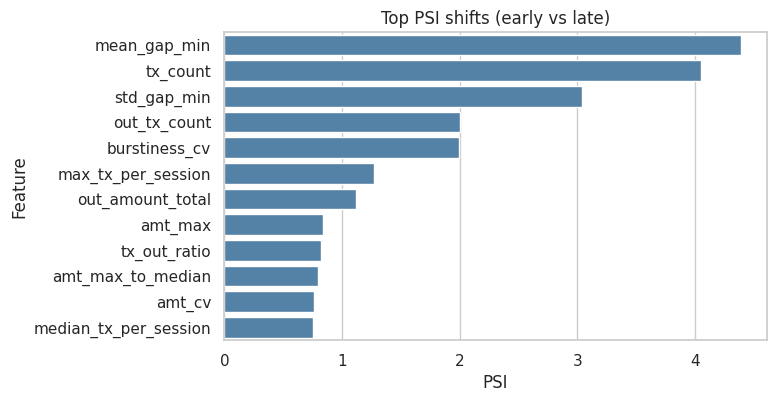

In [10]:
windowed_df = windowed_df.replace([np.inf, -np.inf], np.nan).fillna(0)

periods = sorted(windowed_df['period'].unique())
if len(periods) < 2:
    raise ValueError('Not enough periods for shift detection.')

early_periods = periods[:max(1, len(periods)//3)]
late_periods = periods[-max(1, len(periods)//3):]

early_df = windowed_df[windowed_df['period'].isin(early_periods)]
late_df = windowed_df[windowed_df['period'].isin(late_periods)]

feature_cols = [c for c in windowed_df.columns if c not in ['account_id','period','account_money_launderer']]

def psi_score(expected, actual, buckets=10):
    breakpoints = np.quantile(expected, np.linspace(0, 1, buckets + 1))
    breakpoints[0] = -np.inf
    breakpoints[-1] = np.inf
    expected_counts = np.histogram(expected, bins=breakpoints)[0] / len(expected)
    actual_counts = np.histogram(actual, bins=breakpoints)[0] / len(actual)
    expected_counts = np.clip(expected_counts, 1e-6, None)
    actual_counts = np.clip(actual_counts, 1e-6, None)
    return np.sum((actual_counts - expected_counts) * np.log(actual_counts / expected_counts))

def js_divergence(expected, actual, bins=20):
    hist_expected, bin_edges = np.histogram(expected, bins=bins, density=True)
    hist_actual, _ = np.histogram(actual, bins=bin_edges, density=True)
    hist_expected = np.clip(hist_expected, 1e-6, None)
    hist_actual = np.clip(hist_actual, 1e-6, None)
    return jensenshannon(hist_expected, hist_actual, base=2.0)

drift_rows = []
for col in feature_cols:
    early_vals = early_df[col].values
    late_vals = late_df[col].values
    psi_val = psi_score(early_vals, late_vals)
    js_val = js_divergence(early_vals, late_vals)
    ks_stat, ks_p = ks_2samp(early_vals, late_vals)
    drift_rows.append({
        'feature': col,
        'psi': psi_val,
        'js_divergence': js_val,
        'ks_stat': ks_stat,
        'ks_pvalue': ks_p
    })

drift_df = pd.DataFrame(drift_rows).sort_values('psi', ascending=False)
print(drift_df.head(10))

plt.figure(figsize=(7, 4))
sns.barplot(data=drift_df.head(12), x='psi', y='feature', color='steelblue')
plt.title('Top PSI shifts (early vs late)')
plt.xlabel('PSI')
plt.ylabel('Feature')
plt.show()

### Interpretation — Population drift metrics
The strongest population shifts are in **mean_gap_min (PSI 4.39)**, **tx_count (PSI 4.05)**, **std_gap_min (PSI 3.04)**, and **out_tx_count (PSI 2.01)**. These are timing and volume signals, suggesting that transaction cadence and activity levels changed the most between early and late windows.

For AML goals, such shifts imply that the overall behavioral mix has moved, potentially due to new fraud patterns or increased intensity of suspicious behavior. This is a clear trigger to re-fit clustering models or refresh risk thresholds.

## Step 10 — Embedding drift per account

We project each windowed fingerprint into PCA space and compute the distance between consecutive windows per account. Large distances indicate behavioral instability.

Drift rows: 36
         account_id period_from period_to      drift  account_money_launderer
29             SINK     2025-02   2025-03  40.627008                        1
33  SUSP_RAPID_0007     2025-02   2025-03  12.572655                        1
25      NORM_C_0027     2025-02   2025-03   7.762182                        0
14      NORM_B_0007     2025-02   2025-03   7.140288                        0
16      NORM_B_0032     2025-02   2025-03   6.844319                        0
9       NORM_A_0032     2025-02   2025-03   5.544199                        0
8       NORM_A_0027     2025-02   2025-03   5.337895                        0
3       NORM_A_0015     2025-02   2025-03   4.962397                        0
28      NORM_C_0039     2025-02   2025-03   4.733696                        0
17      NORM_B_0036     2025-02   2025-03   4.433499                        0


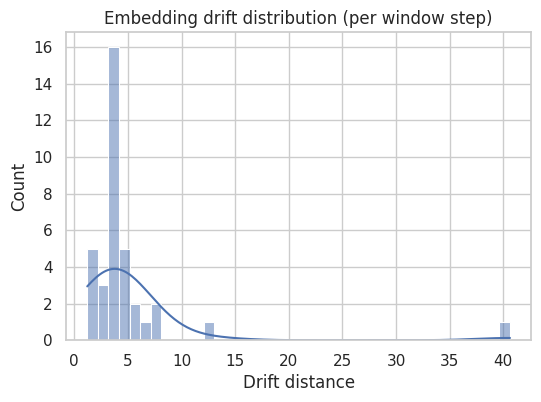

In [11]:
windowed_numeric = windowed_df[feature_cols].values
windowed_scaled = scaler.fit_transform(windowed_numeric)
windowed_pca = PCA(n_components=6, random_state=42).fit_transform(windowed_scaled)

windowed_emb = windowed_df[['account_id','period','account_money_launderer']].copy()
for i in range(windowed_pca.shape[1]):
    windowed_emb[f'pc{i+1}'] = windowed_pca[:, i]

drift_rows = []
for account_id, group in windowed_emb.groupby('account_id'):
    group = group.sort_values('period')
    if len(group) < 2:
        continue
    emb = group[[c for c in group.columns if c.startswith('pc')]].values
    diffs = np.linalg.norm(np.diff(emb, axis=0), axis=1)
    for idx, drift in enumerate(diffs, start=1):
        drift_rows.append({
            'account_id': account_id,
            'period_from': group['period'].iloc[idx-1],
            'period_to': group['period'].iloc[idx],
            'drift': drift,
            'account_money_launderer': group['account_money_launderer'].iloc[0]
        })

drift_df = pd.DataFrame(drift_rows)
print('Drift rows:', len(drift_df))
print(drift_df.sort_values('drift', ascending=False).head(10))

plt.figure(figsize=(6, 4))
sns.histplot(drift_df['drift'], bins=40, kde=True)
plt.title('Embedding drift distribution (per window step)')
plt.xlabel('Drift distance')
plt.show()

### Interpretation — Embedding drift per account
The top drift list highlights outliers such as **SINK (drift 40.63)** and **SUSP_RAPID_0007 (drift 12.57)**, far above the rest. This indicates very large behavior changes over time for those accounts.

Most accounts cluster around lower drift values, which matches the histogram tail: a dense low-drift region with a long tail of extreme shifts. In AML terms, those tail accounts are high-priority review candidates.

## Step 11 — Drift consistency by label

We compare drift distributions for normal vs suspicious accounts to see whether suspicious behavior is more unstable across time windows.

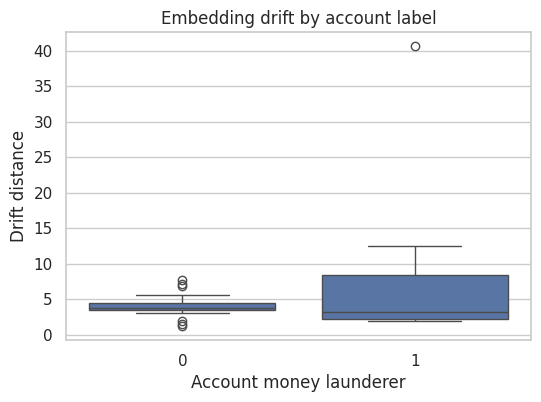

                         count      mean        std       min       25%  \
account_money_launderer                                                   
0                         29.0  4.041156   1.465160  1.210028  3.456047   
1                          7.0  9.579309  14.191409  1.927935  2.246833   

                              50%       75%        max  
account_money_launderer                                 
0                        3.798986  4.433499   7.762182  
1                        3.229266  8.388645  40.627008  


In [12]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=drift_df, x='account_money_launderer', y='drift')
plt.title('Embedding drift by account label')
plt.xlabel('Account money launderer')
plt.ylabel('Drift distance')
plt.show()

print(drift_df.groupby('account_money_launderer')['drift'].describe())

### Interpretation — Drift by label
The summary statistics show **mean drift 4.04** for normal accounts versus **9.58** for suspicious accounts, with a much larger max (**40.63**) in the suspicious group. The box plot reflects this wider spread and higher tail for AML-labeled accounts.

This suggests that suspicious behavior is more volatile in this synthetic dataset. Use this as a prioritization signal rather than proof, since drift can also happen for benign reasons.

## Phase 4 conclusion — Behavioral fingerprinting results
This phase turned account activity into **behavioral fingerprints** and tested whether those fingerprints separate normal vs suspicious patterns and stay stable over time.

**What it's done:** We built compact representations (PCA/UMAP) and clustered accounts with KMeans, GMM, and HDBSCAN. We then measured how fingerprints change month to month and whether the overall population behavior drifted.

**What the results show:** The clustering outputs produced distinct groups with very different AML rates, which means behavior patterns are separable in this feature space. The probe model achieved very high ROC-AUC/PR-AUC, confirming that the fingerprints carry strong fraud signal. Drift analysis showed that timing and volume features shifted most across windows, and a small set of accounts exhibited very large behavior changes, which are exactly the cases AML monitoring should prioritize.

**Why this matters for fraud detection:** These fingerprints give the project a practical way to group similar behaviors, isolate suspicious clusters, and flag accounts that suddenly change behavior. This makes later phases (risk scoring and supervised models) stronger because they can use stable behavior groups and drift signals as inputs.